# Choosing classification thresholds

Choose a cutoff using only saved out-of-fold (OOF) predictions. A row is called flooded when its predicted probability is at least the cutoff. We use the highest cutoff that still reaches the requested recall, which helps reduce false alarms. No model is retrained, and the held-out Imelda test data is not used.

## 1. Load OOF predictions and cleaned training labels

The cleaned training data is used only to map OOF row numbers to storm names and rainfall. Threshold scores come from the saved OOF files.

In [1]:
import sys
from pathlib import Path

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the FloodSense project root from the notebook working directory.")
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.data import load_clean
from src.evaluate import FIGURES_DIR, compute_metrics
from src.threshold import pick_threshold, recall_table

models = ("logistic_regression", "random_forest", "xgboost", "lightgbm")
df = load_clean()
area_oof = {
    model: pd.read_csv(project_root / "reports" / f"oof_{model}_area_group.csv")
    for model in models
}
storm_oof = {
    model: pd.read_csv(project_root / "reports" / f"oof_{model}_leave_one_storm_out.csv")
    for model in models
}
print(f"Loaded {len(df):,} cleaned training rows and saved OOF predictions for {len(models)} models.")

Cleaned training data shape: (66514, 14)
Missing values by column:
year                   0
storm_name             0
storm_date             0
lat                    0
lon                    0
weight                 0
elevation_m            0
slope_degrees          0
distance_to_bayou_m    0
paved_pct              0
land_cover_type        0
rainfall_inches        0
flooded                0
grid_id                0
Loaded 66,514 cleaned training rows and saved OOF predictions for 4 models.


## 2. Choose thresholds on area-group OOF predictions

For each model, scan cutoffs from 0.05 to 0.95 in steps of 0.01 and choose the highest one with recall of at least 0.85. If none meets the target, the chosen cutoff is `None` and the table reports that no cutoff was found.

In [2]:
target_recall = 0.85
threshold_grid = [step / 100 for step in range(5, 96)]
chosen_thresholds = {}
area_rows = []

for model in models:
    threshold = pick_threshold(area_oof[model], target_recall=target_recall)
    chosen_thresholds[model] = threshold
    if threshold is None:
        print(f"{model}: no threshold from 0.05 to 0.95 reaches recall {target_recall:.2f}.")
        area_rows.append({"model": model, "chosen_threshold": None})
        continue
    metrics = compute_metrics(
        area_oof[model]["y_true"], area_oof[model]["y_prob"], threshold
    )
    area_rows.append(
        {
            "model": model,
            "chosen_threshold": threshold,
            "recall": metrics["recall"],
            "precision": metrics["precision"],
            "f1": metrics["f1"],
            "false_alarms": metrics["fp"],
            "missed_floods": metrics["fn"],
        }
    )

area_threshold_table = pd.DataFrame(area_rows)
display(area_threshold_table)

,model,chosen_threshold,recall,precision,f1,false_alarms,missed_floods
0,logistic_regression,0.44,0.854778,0.679846,0.757342,13668,4931
1,random_forest,0.46,0.852363,0.796269,0.823362,7405,5013
2,xgboost,0.51,0.850832,0.815181,0.832625,6550,5065
3,lightgbm,0.51,0.852128,0.816514,0.833941,6502,5021


## 3. Honest check on held-out-storm OOF predictions

The cutoffs below were chosen using area-group OOF predictions, then applied unchanged to leave-one-storm-out OOF predictions. This tests whether a threshold selected in the area folds carries over to a new storm. Overall and per-storm recall and precision are shown.

In [3]:
storm_rows = []
storm_lookup = df[["storm_name"]].copy()

for model in models:
    threshold = chosen_thresholds[model]
    if threshold is None:
        continue
    predictions = storm_oof[model].copy()
    predictions["storm_name"] = storm_lookup["storm_name"].reindex(
        predictions["row_index"].astype(int)
    ).to_numpy()
    if predictions["storm_name"].isna().any():
        raise ValueError(f"Some OOF row_index values for {model} do not map to a storm.")

    overall = compute_metrics(predictions["y_true"], predictions["y_prob"], threshold)
    storm_rows.append(
        {
            "model": model,
            "scope": "overall",
            "threshold": threshold,
            "recall": overall["recall"],
            "precision": overall["precision"],
        }
    )
    for storm_name, group in predictions.groupby("storm_name", sort=True):
        metrics = compute_metrics(group["y_true"], group["y_prob"], threshold)
        storm_rows.append(
            {
                "model": model,
                "scope": storm_name,
                "threshold": threshold,
                "recall": metrics["recall"],
                "precision": metrics["precision"],
            }
        )

storm_check_table = pd.DataFrame(storm_rows)
display(storm_check_table)

,model,scope,threshold,recall,precision
0,logistic_regression,overall,0.44,0.884082,0.652786
1,logistic_regression,Hurricane Harvey,0.44,0.978873,0.607744
2,logistic_regression,Memorial Day Flood,0.44,0.862430,0.672647
3,logistic_regression,Tax Day Flood,0.44,0.804657,0.697879
4,random_forest,overall,0.46,0.600825,0.772443
5,random_forest,Hurricane Harvey,0.46,0.382659,0.753160
6,random_forest,Memorial Day Flood,0.46,0.827514,0.765176
7,random_forest,Tax Day Flood,0.46,0.608774,0.796238
8,xgboost,overall,0.51,0.459638,0.783996
9,xgboost,Hurricane Harvey,0.51,0.063382,0.641026


## 4. LightGBM recall and precision by cutoff

This plot uses LightGBM area-group OOF predictions. The vertical line marks its chosen cutoff.

Saved plot to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\lightgbm_threshold_curve.png


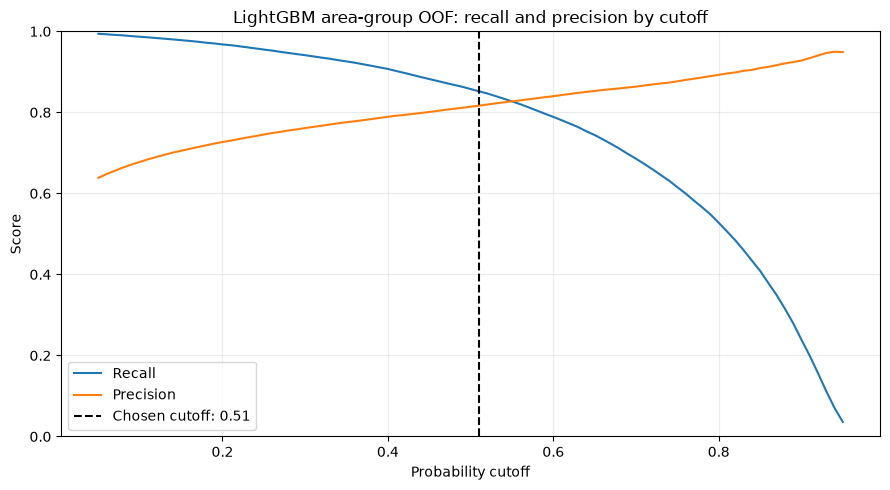

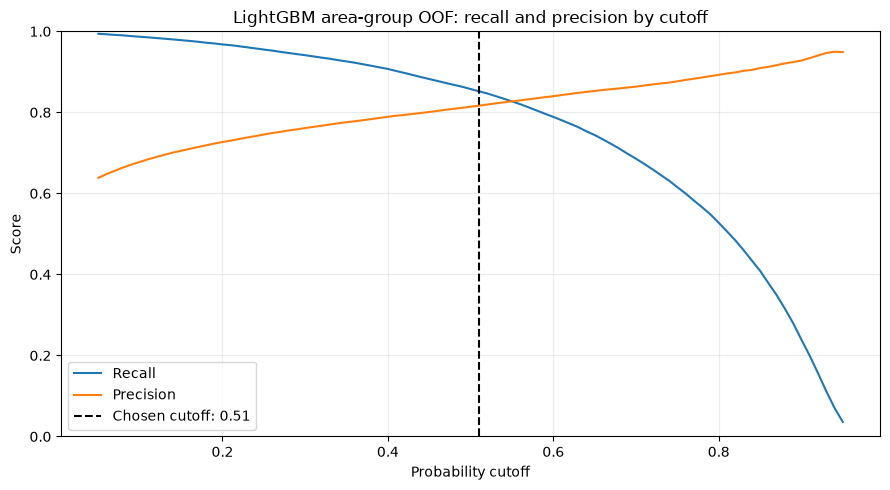

In [4]:
lightgbm_thresholds = recall_table(area_oof["lightgbm"], threshold_grid)
lightgbm_threshold = chosen_thresholds["lightgbm"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(lightgbm_thresholds["threshold"], lightgbm_thresholds["recall"], label="Recall")
ax.plot(lightgbm_thresholds["threshold"], lightgbm_thresholds["precision"], label="Precision")
if lightgbm_threshold is not None:
    ax.axvline(lightgbm_threshold, color="black", linestyle="--", label=f"Chosen cutoff: {lightgbm_threshold:.2f}")
ax.set(xlabel="Probability cutoff", ylabel="Score", title="LightGBM area-group OOF: recall and precision by cutoff")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
threshold_plot_path = FIGURES_DIR / "lightgbm_threshold_curve.png"
fig.savefig(threshold_plot_path, dpi=150, bbox_inches="tight")
print(f"Saved plot to {threshold_plot_path}")
display(fig)

## 5. LightGBM score and rainfall patterns by storm

For each storm, compare the average LightGBM OOF score for flooded and non-flooded rows with the average rainfall recorded in the cleaned training data. Differences describe the observed data only; they do not explain why scores differ.

In [5]:
lightgbm_storm = storm_oof["lightgbm"].copy()
lightgbm_storm["storm_name"] = storm_lookup["storm_name"].reindex(
    lightgbm_storm["row_index"].astype(int)
).to_numpy()
if lightgbm_storm["storm_name"].isna().any():
    raise ValueError("Some LightGBM OOF row_index values do not map to a storm.")

score_means = lightgbm_storm.groupby(["storm_name", "y_true"])["y_prob"].mean().unstack("y_true")
score_means = score_means.rename(
    columns={0: "mean_probability_flooded_0", 1: "mean_probability_flooded_1"}
)
rainfall_means = df.groupby("storm_name")["rainfall_inches"].mean().rename("mean_rainfall_inches")
lightgbm_storm_summary = score_means.join(rainfall_means, how="outer").reset_index()
display(lightgbm_storm_summary)

for column, label in (
    ("mean_probability_flooded_1", "flooded rows"),
    ("mean_probability_flooded_0", "non-flooded rows"),
):
    means = lightgbm_storm_summary.set_index("storm_name")[column].dropna()
    low_storm, high_storm = means.idxmin(), means.idxmax()
    print(
        f"For {label}, average LightGBM scores range from {means[low_storm]:.3f} "
        f"({low_storm}) to {means[high_storm]:.3f} ({high_storm})."
    )
print("The average scores differ across storms; these numbers show a pattern, not its cause.")

,storm_name,mean_probability_flooded_0,mean_probability_flooded_1,mean_rainfall_inches
0,Hurricane Harvey,0.112911,0.255739,12.828799
1,Memorial Day Flood,0.232267,0.621376,6.549880
2,Tax Day Flood,0.197366,0.564435,5.718180


For flooded rows, average LightGBM scores range from 0.256 (Hurricane Harvey) to 0.621 (Memorial Day Flood).
For non-flooded rows, average LightGBM scores range from 0.113 (Hurricane Harvey) to 0.232 (Memorial Day Flood).
The average scores differ across storms; these numbers show a pattern, not its cause.


## 6. Save the selected cutoffs and check metrics

The area-group row records the threshold selection results. The storm-holdout row applies that same area-chosen threshold without changing it.

In [6]:
threshold_rows = []
for model in models:
    threshold = chosen_thresholds[model]
    for split_name, oof_df in (
        ("area_group", area_oof[model]),
        ("leave_one_storm_out", storm_oof[model]),
    ):
        if threshold is None:
            recall = precision = float("nan")
        else:
            metrics = compute_metrics(oof_df["y_true"], oof_df["y_prob"], threshold)
            recall, precision = metrics["recall"], metrics["precision"]
        threshold_rows.append(
            {
                "model": model,
                "split": split_name,
                "threshold": threshold,
                "target_recall": target_recall,
                "recall": recall,
                "precision": precision,
            }
        )

thresholds_df = pd.DataFrame(
    threshold_rows,
    columns=["model", "split", "threshold", "target_recall", "recall", "precision"],
)
thresholds_path = project_root / "reports" / "thresholds.csv"
thresholds_df.to_csv(thresholds_path, index=False)
print(f"Saved threshold results to {thresholds_path}")
display(thresholds_df)

Saved threshold results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\thresholds.csv


,model,split,threshold,target_recall,recall,precision
0,logistic_regression,area_group,0.44,0.85,0.854778,0.679846
1,logistic_regression,leave_one_storm_out,0.44,0.85,0.884082,0.652786
2,random_forest,area_group,0.46,0.85,0.852363,0.796269
3,random_forest,leave_one_storm_out,0.46,0.85,0.600825,0.772443
4,xgboost,area_group,0.51,0.85,0.850832,0.815181
5,xgboost,leave_one_storm_out,0.51,0.85,0.459638,0.783996
6,lightgbm,area_group,0.51,0.85,0.852128,0.816514
7,lightgbm,leave_one_storm_out,0.51,0.85,0.464998,0.791270


**My observations:**